In [1]:
# --- project root: run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: <project folder>


# 17b — Round 7 preprocessing → `data_r7/` (keeps `data_r5/` unchanged)

* The **new training regions** from 17a are cut into tiles exactly like before (same clipping, labels, 256 px tiles, stride 236).
* The **old tiles are not copied**: `data_r7/patch_index.csv` points to them in `data_r5/` (paths start with `../data_r5/`),
  so no disk space is wasted and validation / test tiles are *identical* to round 5 and 6.
* Normalisation statistics and class weights are recomputed from the new (bigger) training set.

In [2]:
import sys, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm

sys.path.append(".")
from preprocess import (CLASSES, COLORS, IGNORE, BANDS, CLIP, decode_s1, clip_db,
                        remap_worldcover, normalise)

YEAR    = 2021
DATA    = Path("data_r7")                  # round-7 output folder
OLD     = Path("data_r5")                  # round-5 tiles are reused, not copied
RAW     = Path("data") / "raw"             # shared raw downloads (read only)
DATA.mkdir(exist_ok=True)
PATCHES = DATA / "patches"
PATCH   = 256
SPECKLE_FILTER = False      # extra 3x3 median filter; keep False for the baseline (test it later as a model variant)
random.seed(42); np.random.seed(42)

regions = pd.read_csv(Path("data") / "regions_r7.csv")
new_regions = regions[regions["round"] == 7]
cmap = ListedColormap(COLORS)
print(regions.split.value_counts().to_string())
print("new training regions:", ", ".join(new_regions.name))

split
train    58
val       8
test      6
new training regions: thai_rice, bangladesh_rice, bengal_rice, cauvery_rice, java_rice, luzon_rice, arkansas_rice, sacramento_rice, vercelli_rice, ibera_wetland, kakadu_floodplain, donana_marsh, niger_mangrove, hudson_lowlands, vasyugan_bog, patagonia_steppe, texas_rangeland, australia_shrub, kuala_lumpur, chennai


In [3]:
def load_region(name):
    with rasterio.open(RAW / f"{name}_s1_{YEAR}.tif") as f:
        raw = f.read()                                   # (36, H, W) int16
    with rasterio.open(RAW / f"{name}_label.tif") as f:
        wc = f.read(1)                                   # WorldCover codes
    x = decode_s1(raw.reshape(12, 3, *raw.shape[1:]))    # (12, 3, H, W) dB, NaN = no data
    return x, remap_worldcover(wc)                       # y: 0..6, 255 = ignore

x, y = load_region("thai_rice")
print("x shape (month, band, H, W):", x.shape, "| y shape:", y.shape)
print("no-data share per month (%):", np.round(np.isnan(x[:, 0]).mean((1, 2)) * 100, 1))
for b, name in enumerate(BANDS):
    v = x[:, b]
    print(f"{name:6s} min {np.nanmin(v):7.1f}  1% {np.nanpercentile(v, 1):6.1f}  "
          f"median {np.nanmedian(v):6.1f}  99% {np.nanpercentile(v, 99):6.1f}  max {np.nanmax(v):6.1f}")

x shape (month, band, H, W): (12, 3, 1200, 1200) | y shape: (1200, 1200)
no-data share per month (%): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
VV     min   -28.4  1%  -17.1  median   -9.6  99%   -3.9  max   17.8
VH     min   -35.1  1%  -25.5  median  -16.5  99%  -12.0  max   10.4
VV_VH  min   -12.4  1%    2.4  median    6.8  99%   14.3  max   31.2


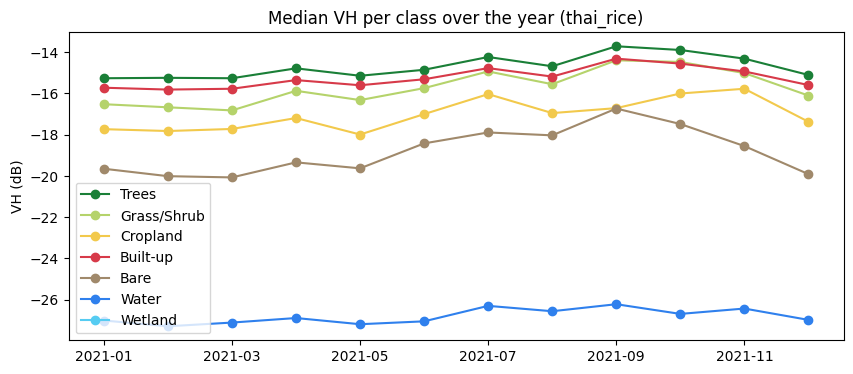

In [4]:
# How each class changes over the year (median VH per month) — the seasonal effect
med = pd.DataFrame({cname: [np.nanmedian(x[m, 1][y == c]) if (y == c).sum() > 500 else np.nan
                            for m in range(12)] for c, cname in enumerate(CLASSES)},
                   index=[f"{YEAR}-{m + 1:02d}" for m in range(12)])
ax = med.plot(figsize=(10, 4), color=[COLORS[CLASSES.index(c)] for c in med.columns], marker="o",
              title="Median VH per class over the year (thai_rice)")
ax.set_ylabel("VH (dB)"); plt.show()

**Rice:** cropland VH should drop in the flooding months and rise quickly afterwards — this is the pattern v7 should learn as *Cropland*.

## 1. Cut tiles for the new regions and build the combined index

In [5]:
def positions(size, stride, patch=PATCH):
    p = list(range(0, size - patch + 1, stride))
    if p[-1] != size - patch and stride < patch:      # make sure the last row/column is covered
        p.append(size - patch)
    return p

(PATCHES / "train").mkdir(parents=True, exist_ok=True)
new_index = []
for r in tqdm(list(new_regions.itertuples()), desc="new regions"):
    if not (RAW / f"{r.name}_s1_{YEAR}.tif").exists():
        print("missing download, skipped:", r.name); continue
    x, y = load_region(r.name)
    x = clip_db(x)
    H, W = y.shape
    for i in positions(H, 236):
        for j in positions(W, 236):
            yp = y[i:i + PATCH, j:j + PATCH]
            if (yp == IGNORE).mean() > 0.5:
                continue
            xp = x[:, :, i:i + PATCH, j:j + PATCH].astype(np.float16)
            fname = PATCHES / "train" / f"{r.name}_{i:04d}_{j:04d}.npz"
            if not fname.exists():
                np.savez_compressed(fname, x=xp, y=yp)
            counts = np.bincount(yp[yp != IGNORE], minlength=len(CLASSES))
            new_index.append({"file": fname.relative_to(DATA).as_posix(), "region": r.name, "split": "train",
                              "row": i, "col": j, **dict(zip(CLASSES, counts)),
                              "nodata_%": float(np.isnan(xp[:, 0]).mean() * 100)})
new_index = pd.DataFrame(new_index)

old_index = pd.read_csv(OLD / "patch_index.csv")
old_index["file"] = "../data_r5/" + old_index["file"].str.replace("\\", "/", regex=False)
index = pd.concat([old_index, new_index], ignore_index=True)
assert all((DATA / f).exists() for f in index.file), "some tile files are missing"
index.to_csv(DATA / "patch_index.csv", index=False)
print("new training tiles:", len(new_index))
print(index.groupby("split").size().rename("tiles (round 7)").to_frame().join(
      old_index.groupby("split").size().rename("tiles (round 5)")).to_string())

new regions:   0%|          | 0/20 [00:00<?, ?it/s]

new training tiles: 500
       tiles (round 7)  tiles (round 5)
split                                  
test                96               96
train             1450              950
val                128              128


## 2. Normalisation statistics — training regions only

Normalisation rescales each band to mean ≈ 0, std ≈ 1 so the network trains stably.
The mean and std are computed **only from training patches** (all months, valid pixels). Using validation or test data here would be *data leakage*.
The same numbers are used later for val/test and in the prototype.

In [6]:
n = np.zeros(3); s = np.zeros(3); ss = np.zeros(3)
for f in tqdm(index[index.split == "train"].file, desc="stats"):
    xp = np.load(DATA / f)["x"].astype(np.float64)                 # (12, 3, 256, 256)
    for b in range(3):
        v = xp[:, b][~np.isnan(xp[:, b])]
        n[b] += v.size; s[b] += v.sum(); ss[b] += (v ** 2).sum()
mean = s / n
std = np.sqrt(ss / n - mean ** 2)
for b, name in enumerate(BANDS):
    print(f"{name:6s} mean {mean[b]:7.2f} dB   std {std[b]:5.2f} dB")

stats:   0%|          | 0/1450 [00:00<?, ?it/s]

VV     mean  -11.10 dB   std  4.90 dB
VH     mean  -18.68 dB   std  5.19 dB
VV_VH  mean    7.56 dB   std  2.78 dB


## 3. Class distribution and class weights

Required in the report. Pixels are counted once per patch (the same label is used for all 12 months).
Class weights `1 / sqrt(frequency)` (normalised to mean 1) are saved for the loss function, so rare classes are not ignored.

Pixels per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
split,,,,,,,
train,12462446,20129669,22723983,14871139,6680054,7340301,10819608
val,930014,1891093,835340,2583199,133015,273214,1742733
test,1341659,1017776,711627,1379209,1087194,252109,501882


Share per class (%)


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
split,,,,,,,
train,13.11,21.18,23.91,15.65,7.03,7.72,11.39
val,11.09,22.54,9.96,30.79,1.59,3.26,20.77
test,21.33,16.18,11.31,21.92,17.28,4.01,7.98


Class weights: {'Trees': np.float64(0.97), 'Grass/Shrub': np.float64(0.77), 'Cropland': np.float64(0.72), 'Built-up': np.float64(0.89), 'Bare': np.float64(1.33), 'Water': np.float64(1.27), 'Wetland': np.float64(1.05)}


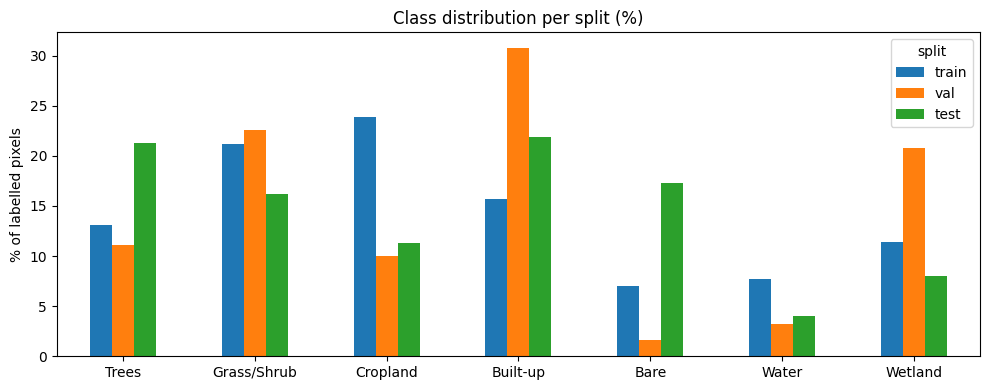

Training share per class: round 5 -> round 7 (%)


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
round 5,11.42,20.92,19.53,19.19,9.96,10.00,8.98
round 7,13.11,21.18,23.91,15.65,7.03,7.72,11.39


In [7]:
dist = index.groupby("split")[CLASSES].sum().loc[["train", "val", "test"]]
dist_pct = (100 * dist.div(dist.sum(axis=1), axis=0)).round(2)
dist.to_csv(DATA / "class_distribution_pixels.csv"); dist_pct.to_csv(DATA / "class_distribution.csv")
print("Pixels per class"); display(dist)
print("Share per class (%)"); display(dist_pct)

freq = dist.loc["train"].values / dist.loc["train"].values.sum()
weights = 1 / np.sqrt(np.maximum(freq, 1e-6)); weights = weights / weights.mean()
print("Class weights:", dict(zip(CLASSES, np.round(weights, 2))))

ax = dist_pct.T.plot.bar(figsize=(10, 4), rot=0, title="Class distribution per split (%)")
ax.set_ylabel("% of labelled pixels"); plt.tight_layout()
plt.savefig(DATA / "class_distribution.png", dpi=150); plt.show()

old_pct = pd.read_csv(OLD / "class_distribution.csv", index_col=0)
print("Training share per class: round 5 -> round 7 (%)")
display(pd.DataFrame({"round 5": old_pct.loc["train"], "round 7": dist_pct.loc["train"]}).T)

In [8]:
stats = {
    "bands": BANDS, "units": "dB, clipped", "clip": CLIP,
    "mean": mean.round(4).tolist(), "std": std.round(4).tolist(),
    "classes": CLASSES, "ignore_index": IGNORE,
    "class_weights": np.round(weights, 4).tolist(),
    "year": YEAR, "patch_size": PATCH, "speckle_filter": SPECKLE_FILTER,
    "train_regions": sorted(regions[regions.split == "train"].name),
    "val_regions":   sorted(regions[regions.split == "val"].name),
    "test_regions":  sorted(regions[regions.split == "test"].name),
}
with open(DATA / "norm_stats.json", "w") as f:
    json.dump(stats, f, indent=2)
print(json.dumps(stats, indent=2)[:600], "...")

{
  "bands": [
    "VV",
    "VH",
    "VV_VH"
  ],
  "units": "dB, clipped",
  "clip": {
    "VV": [
      -25.0,
      5.0
    ],
    "VH": [
      -32.0,
      -5.0
    ],
    "VV_VH": [
      0.0,
      20.0
    ]
  },
  "mean": [
    -11.0976,
    -18.6786,
    7.5603
  ],
  "std": [
    4.902,
    5.1927,
    2.7758
  ],
  "classes": [
    "Trees",
    "Grass/Shrub",
    "Cropland",
    "Built-up",
    "Bare",
    "Water",
    "Wetland"
  ],
  "ignore_index": 255,
  "class_weights": [
    0.9743,
    0.7666,
    0.7215,
    0.8919,
    1.3307,
    1.2695,
    1.0456
  ],
  "year": 2021,
 ...


## 4. Final checks before training

1. No region appears in two splits.
2. Normalised training data has mean ≈ 0 and std ≈ 1.
3. Every class appears in every split.
4. Random patches look right: bright built-up in VV, dark water, label lines up.

1. Splits are disjoint by region ✔
2. normalised mean per band: [-0.09 -0.11  0.05] | std: [1.01 1.   1.03]
3. Missing classes: none ✔


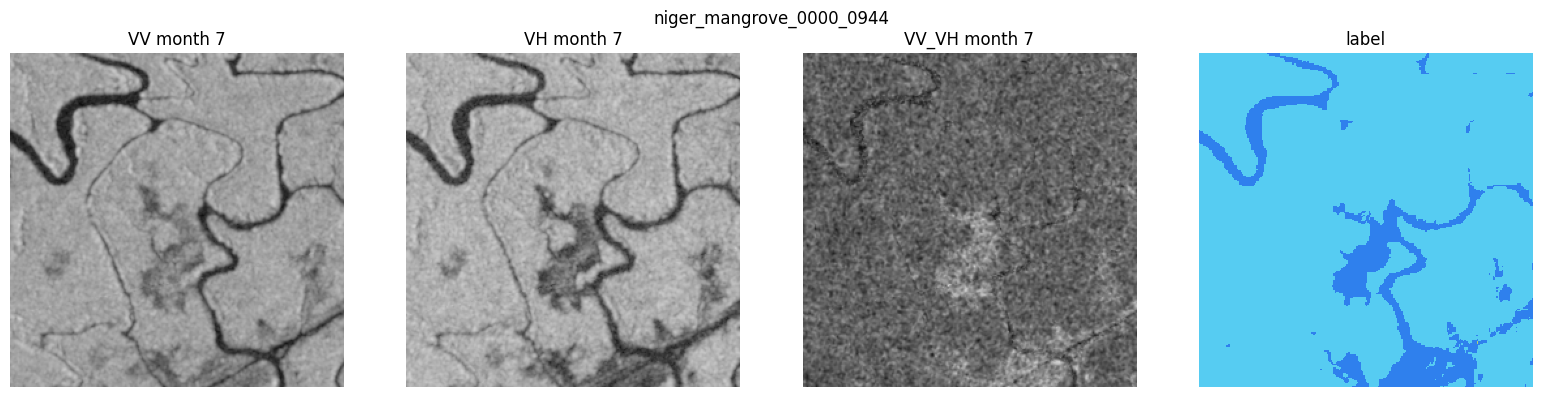

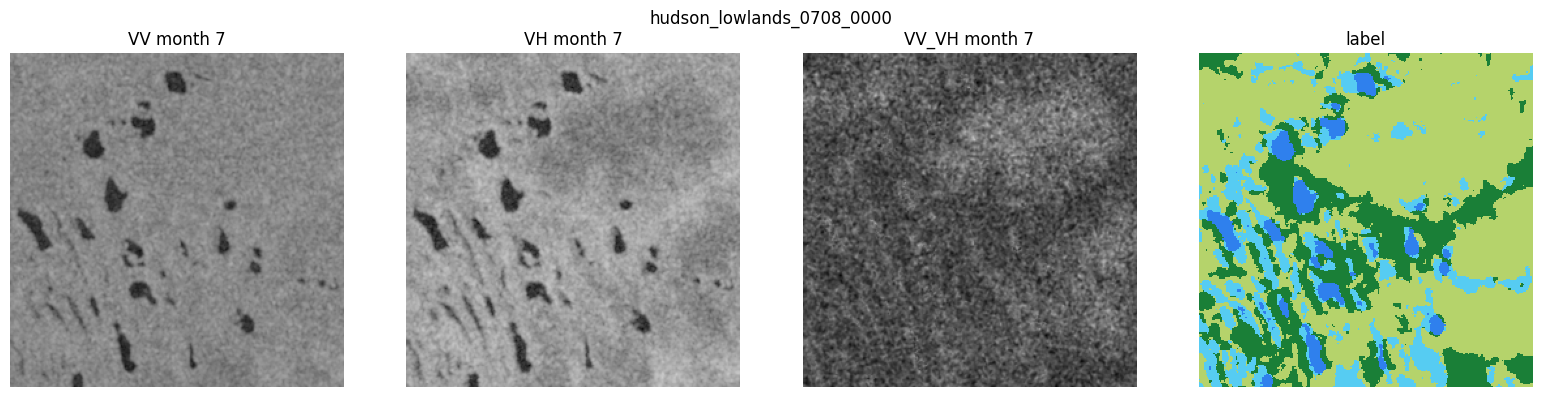

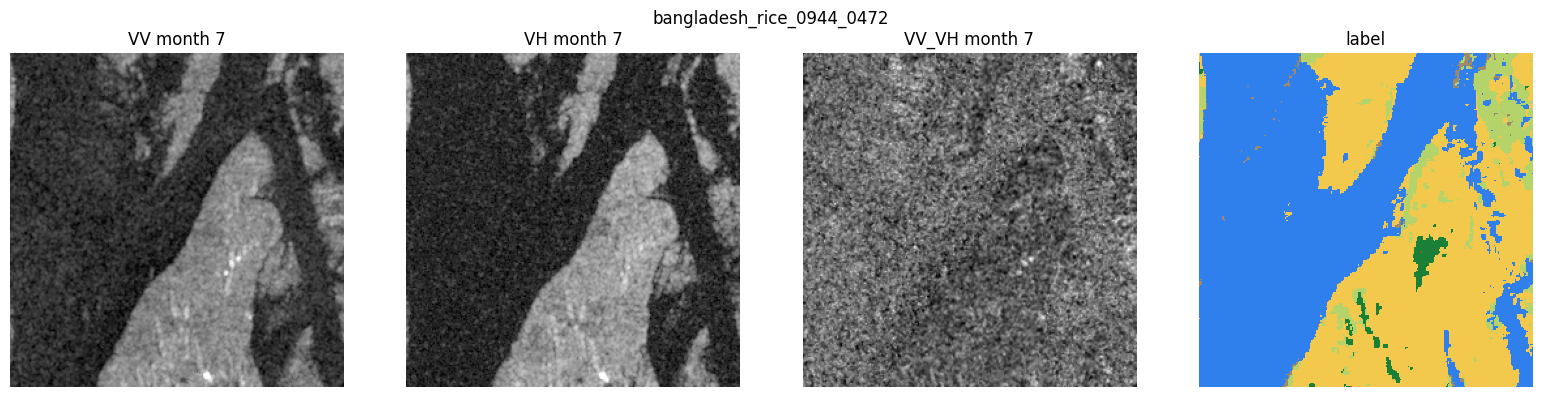

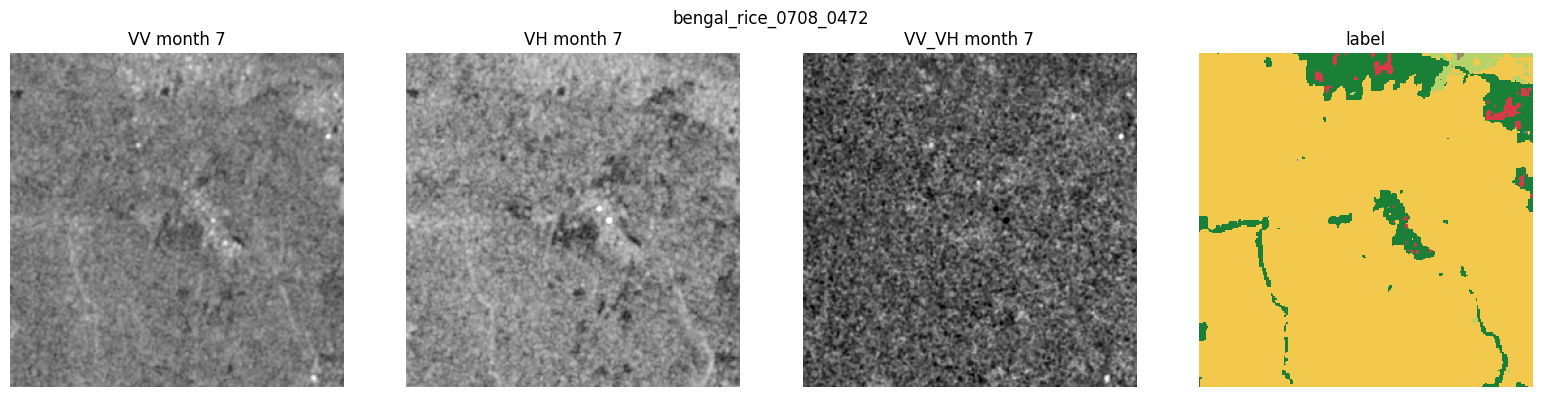

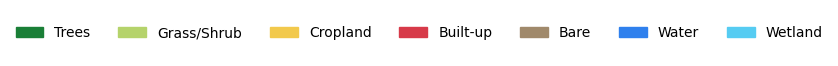

In [9]:
# 1. no region in two splits
sets = {s: set(index[index.split == s].region) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("1. Splits are disjoint by region ✔")

# 2. normalisation check on 30 random training patches
sample = [np.load(DATA / f)["x"].astype(np.float32) for f in index[index.split == "train"].file.sample(30, random_state=0)]
z = np.stack([normalise(xp, stats) for xp in sample])           # (30, 12, 3, 256, 256)
print("2. normalised mean per band:", np.round(z.mean((0, 1, 3, 4)), 2), "| std:", np.round(z.std((0, 1, 3, 4)), 2))

# 3. every class in every split
missing = [(s, c) for s in dist.index for c in CLASSES if dist.loc[s, c] == 0]
print("3. Missing classes:", missing if missing else "none ✔")

# 4. visual check
def show_patch(f, month=6):
    d = np.load(DATA / f); xp, yp = d["x"].astype(np.float32), d["y"]
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    for b, (a, name) in enumerate(zip(ax, BANDS)):
        a.imshow(xp[month, b], cmap="gray", vmin=CLIP[name][0], vmax=CLIP[name][1]); a.set_title(f"{name} month {month + 1}")
    ax[3].imshow(np.ma.masked_equal(yp, IGNORE), cmap=cmap, vmin=0, vmax=6, interpolation="nearest")
    ax[3].set_title("label")
    for a in ax: a.axis("off")
    fig.suptitle(Path(f).stem); plt.tight_layout(); plt.show()

for f in new_index.sample(4, random_state=1).file:
    show_patch(f)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS]
plt.figure(figsize=(10, 0.6)); plt.legend(handles, CLASSES, ncol=7, loc="center", frameon=False); plt.axis("off"); plt.show()

In [10]:
total_mb = sum((DATA / f).stat().st_size for f in index.file) / 1e6
print(f"Patches: {len(index)}  |  size on disk: {total_mb / 1e3:.2f} GB")
print("Training samples per epoch (one random month per patch):", (index.split == 'train').sum())
print("Val/test samples (all 12 months):", 12 * (index.split != 'train').sum())

Patches: 1674  |  size on disk: 5.84 GB
Training samples per epoch (one random month per patch): 1450
Val/test samples (all 12 months): 2688


✅ **Ready for training:** continue with **18_train_v7_more_regions.ipynb**.